# 7: Unsupervised Learning (Part 2: PCA)

## 1. Power Iteration

The Power Iteration method is a relatively simple method for calculating eigenvectors for a square $(D × D)$ matrix $M$. The process works as follows:  
A. Construct a vector $\mathbf{v}_0$ of ones of length $D × 1$.  
B. Until convergence, compute:  

$\mathbf{v}_{k+1} = \dfrac{M \cdot\mathbf{v}_{k}}{||M \cdot \mathbf{v}_{k}||}$, where  
$||M \cdot \mathbf{v}_{k}||$ is the L2 norm of $M\mathbf{v}_{k}$.

C. Output vector $\mathbf{v}$ as the principal eigenvector of $M$.  
D. Compute $M^∗$ as:  

$λ = \mathbf{v}^\intercal \cdot M \cdot \mathbf{v}$  
$M^∗ = M − λ × \mathbf{v \cdot v}^\intercal$

E. If more eigenvectors are required, go to step 1 with $M^∗$ as input.

In [13]:
import numpy as np
import numpy.linalg as la

def power_iteration(matrix, n_vectors, e):
    assert matrix.shape[0] == matrix.shape[1]
    assert 0 < n_vectors <= matrix.shape[0]
    assert e > 0

    eigen_vectors = []
    matrix = matrix.astype(float).copy()
    D = matrix.shape[0]

    for i in range(n_vectors):
        v = np.ones(D)
        v = v / la.norm(v)
        while True:
            current = matrix @ v
            current = current / la.norm(current)

            difference = min(la.norm(current - v), la.norm(current + v) )

            v = current

            if difference < e:
                break

        eigen_vectors.append(v)

        # Remove this eigenvector's contribution
        eigen_value = v @ matrix @ v
        matrix = matrix - eigen_value * np.outer(v, v)

    return eigen_vectors

Each column tells a dimension, so a DxD matrix will have D eigenvectors because they live in a D-dimensional space 

For the next exercise, you will need to read data from a file. Use the `read_data` function below to do this.

In [14]:
def read_data(file_name):
    """
    This function loads a given matrix data file into a numpy matrix.
    :param file_name: name of the file to be read
    :return: the data as a numpy array
    """
    lines = [line.rstrip('\n') for line in open(file_name)]

    result = np.zeros((len(lines), len(lines[0].split(" "))))

    for (i, line) in enumerate(lines):
        line = line.split(" ")
        for (j, number) in enumerate(line):
            result[i][j] = float(number)

    return result

 $\ex{1.2}$ Create a matrix and let it read the data from `data/matrix.txt`. Use the `power_iteration()` method to calculate two eigenvectors from this matrix (and set `e` to a reasonably small value, e.g. $10E-5$). Verify that the resulting eigenvectors are roughly equal to:
 
$v_1 = \begin{bmatrix}0.4472 \\ 0.8944\end{bmatrix}$
$v_2 = \begin{bmatrix}0.8944 \\ -0.4472\end{bmatrix}$

In [15]:
e = 10e-5 

matrix = read_data("data/matrix.txt")

eigenvectors = power_iteration(matrix, 2, e) 

v1 = eigenvectors[0]

v2 = eigenvectors[1]

print("v1:", v1)
print("v2:", v2)

v1: [0.44722684 0.89442057]
v2: [ 0.89440402 -0.44725993]


$\q{1.3}$ Are the eigenvalues of these eigenvectors increasing or decreasing as you compute more eigenvectors? What do these eigenvalues say about the eigenvectors?

## 2: Principal Component Analysis

Next, we will use Principal Component Analysis to find the principal components in a dataset. 
Principal components can be seen as vectors along which most variance is found in the data. 

We will now create a matrix that reads data from `data/gaussian.txt`. The size of this matrix is $N × 2$, where $N$ is the number of points in the dataset. Then, we will use `plot_data()` to plot the data.

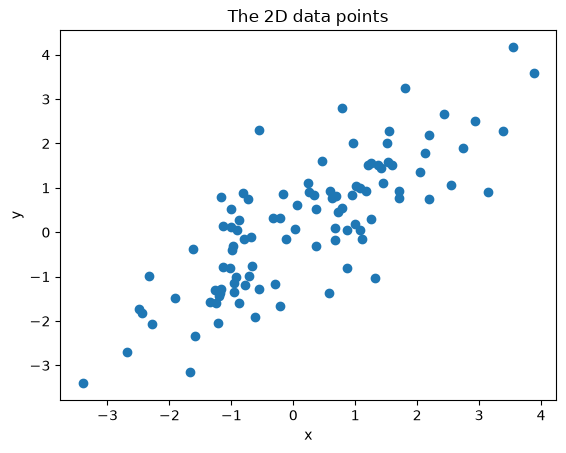

In [16]:
import matplotlib.pyplot as plt
%matplotlib inline

def plot_data(data, eigen_vectors = None):
    """
    This function plots the data of the given `eigen_vectors` with a scatterplot of the matrix data. 
    If no eigenvectors are available, it just plots the data
    :param data: the data
    :param eigen_vectors: the eigenvectors
    """
    # Plot the features as a scatterplot
    x = [[el[0]] for el in data]
    y = [[el[1]] for el in data]
    plt.scatter(x, y)
    
    if eigen_vectors:
        # Plot the two PCA lines
        for vector in eigen_vectors:
            line = _set_line(vector)
            plt.plot(line[0], line[1], 'red')

    plt.show()
    
def _set_line(vector):
    # Fixed number for the line size of this plot
    line_size = 6

    # Set the coordinates for the PCA lines
    axis = np.zeros((2, 2))
    axis[0][0] = vector[0] * line_size
    axis[1][0] = vector[1] * line_size
    axis[0][1] = vector[0] * -line_size
    axis[1][1] = vector[1] * -line_size
    return axis

data = read_data("data/gaussian.txt")
plt.title('The 2D data points')
plt.xlabel('x')
plt.ylabel('y')
plot_data(data)

The first principal component is going to be alongside the obvious diagonal, while the second component i s going to be perpendicular to the first one, thus running from top left to bottom right corner

$\ex{2.1}$
The principal components of a dataset can also be seen as the eigenvectors of the covariance
matrix. Compute the covariance matrix of the Gaussian dataset as follows:  
  
$cov(X) = \dfrac{1}{N}(X - \bar{x})^\intercal(X - \bar{x})$

where $\bar{x}$ is a vector containing the mean of each feature. Next, compute the eigenvectors of this covariance matrix and plot the vectors accordingly.

In [19]:
def covariance(data):
    """
    This function computes the computes the covariance matrix of a given `data`.
    :param data: the starting data
    :return: the covariance matrix 
    """
    miu = np.mean(data, axis=0)
    centered_zero_mean = data - miu 

    matrix = 1/len(data) * (centered_zero_mean.T @ centered_zero_mean)

    return matrix

In [20]:
# Now let's check your implementation with the numpy built-in cov function. 
data = read_data("data/gaussian.txt")
your_cov_matrix = covariance(data)
np_cov_matrix = np.cov(np.transpose(data))

# Your value might differ slightly as the numpy built-in cov function is a bit more precise than our function :).
err_msg = "Your covariance matrix is allowed to differ from the numpy matrix, but no more than ~+-0.025"
np.testing.assert_allclose(np_cov_matrix, your_cov_matrix, atol=0.025, err_msg=err_msg)

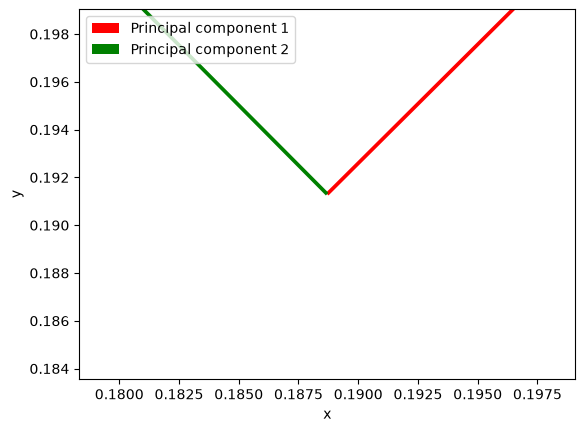

In [21]:
# Use power iteration method to compute the eigenvectors using your covariance matrix and plot the resulting vectors.
# The plot should contain both the dataset (like in the above plot) and the eigenvectors.

cov_matrix = covariance(data) 

eigenvectors = power_iteration(cov_matrix, 2, 1e-5)

miu = np.mean(data, axis=0)


for i in range(2):
    v = eigenvectors[i]
    plt.quiver(miu[0], miu[1], v[0], v[1], angles='xy', scale_units='xy', scale=1,color=['red', 'green'][i], label=f'Principal component {i + 1}')

plt.xlabel('x')
plt.ylabel('y')
plt.axis('equal')
plt.legend()
plt.show()



The first principal component (red) captures the most variance because it follows the direction in which the data is most spread out. It corresponds to the largest eigenvalue of the covariance matrix

For the next exercise, you will need to use the `create_image` function presented below.  
__Note:__ If you have trouble installing PIL, try ```pip install Pillow```.

In [25]:
import math
from PIL import Image

def create_image(fv):
    """
    This function creates a grey image based on the given feature vector `fv`.
    :param fv: the feature vector
    :param title: the title of the image
    """
    width = height = int(math.sqrt(len(fv)))

    # Filter label and threshold from data
    img = Image.new('L', (width, height), "black")
    pixels = img.load()
    min_v = min(fv)
    max_v = max(fv)

    # Iterate over each pixel and set p value
    j = 0
    for (idx, p) in enumerate(fv):
        i = idx % width
        pixel = int(((p - min_v) / (max_v - min_v) * 255))
        pixels[i, j] = pixel
        if i == (width - 1):
            j += 1

    # Resize image to make it better visible
    img = img.resize((256, 256), Image.ANTIALIAS)
    return img

Mean image


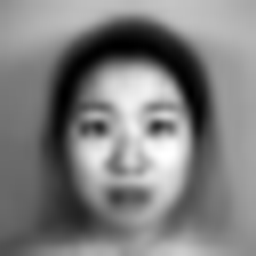

Principal component 1


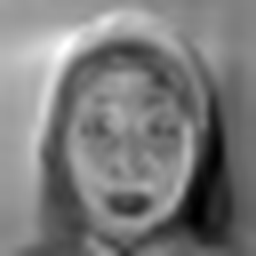

Principal component 2


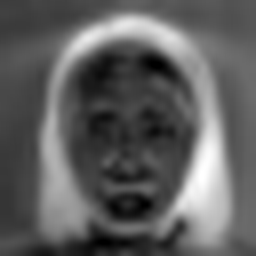

Principal component 3


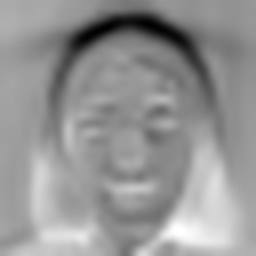

Principal component 4


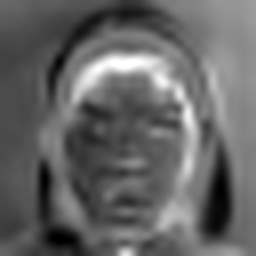

Principal component 5


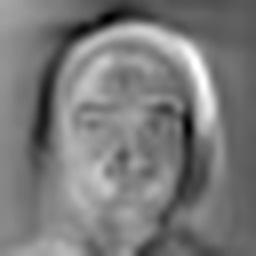

Principal component 6


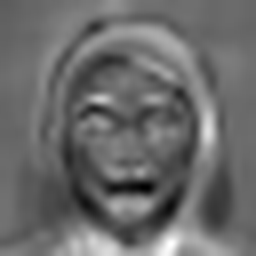

Principal component 7


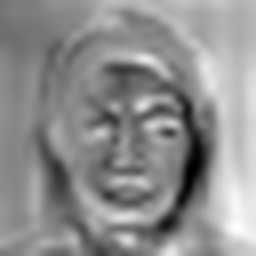

Principal component 8


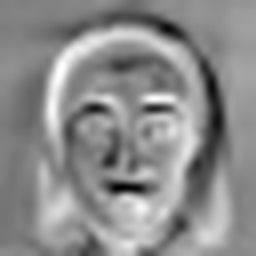

Principal component 9


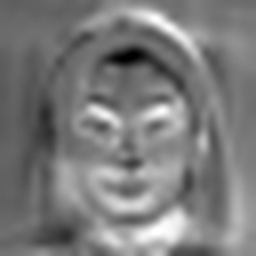

Principal component 10


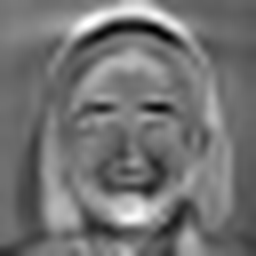

In [27]:
import numpy as np
from PIL import Image
from IPython.display import display

def create_image(vector):
    pixels = np.asarray(vector, dtype=float).reshape(32, 32)

    # Scale pixel values to the range 0–255
    minimum = pixels.min()
    maximum = pixels.max()

    if maximum > minimum:
        pixels = (pixels - minimum) / (maximum - minimum)
    else:
        pixels = np.zeros_like(pixels)

    pixels = (pixels * 255).astype(np.uint8)

    img = Image.fromarray(pixels)
    img = img.resize((256, 256), Image.Resampling.LANCZOS)
    return img


data = read_data("data/faces.txt")

# Display the mean face
mean = np.mean(data, axis=0)
print("Mean image")
display(create_image(mean))

# Display the first 10 eigenfaces
# START ANSWER
cov_matrix = covariance(data)
eigenvectors = power_iteration(cov_matrix, 10, 1e-5)

for i in range(10):
    print("Principal component", i + 1)
    display(create_image(eigenvectors[i]))
# END ANSWER


These principal components, called eigenfaces, represent patterns of variation between faces, such as differences in lighting, facial shape, and features. The first component captures the most variation, while each subsequent component captures less. A face can be approximated by adding a weighted combination of these eigenfaces to the mean face.


PCA can represent a face using a small number of weights instead of all 1024 pixel values. These weights describe how to combine the eigenfaces with the mean face to approximate the original image. This is useful for image compression, noise reduction, and face recognition, where faces can be compared using their weights.